In [ ]:
#Handling Missing Data numerical
#mean or median data imputation
# arbitartry data imputation
# end of data distribution (nmar: Not missing at random)
# 

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [4]:
df=pd.read_csv('titanic/train.csv')

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
x_train,x_test,y_train,y_test=train_test_split(df.drop('Survived',axis=1),df['Survived'],test_size=0.2)

In [8]:
imputer2=SimpleImputer(strategy='mean')
imputer1=SimpleImputer(strategy='median')

In [9]:
trf=ColumnTransformer([
    ('imputer1',imputer1,['Age']),
    ('imputer2',imputer2,['Fare'])
], remainder='passthrough')

In [10]:
trf.fit(x_train)

/home/abhishek/.local/lib/python3.12/site-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('imputer1', SimpleImputer(strategy='median'),
                                 ['Age']),
                                ('imputer2', SimpleImputer(), ['Fare'])])

In [17]:
x_train_trf=trf.transform(x_train)
x_test_trf=trf.transform(x_test)
# ye sab krne ke baad variance jada change nhi hone chaiye  red flag

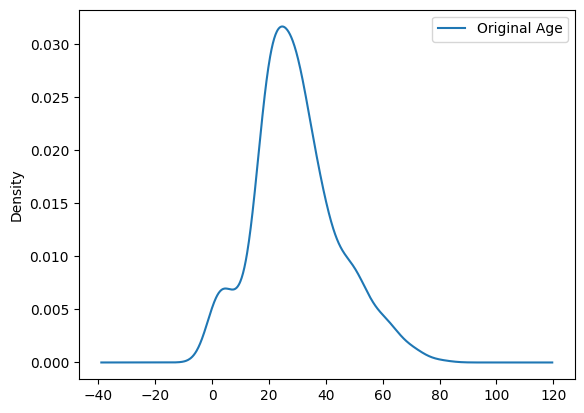

In [19]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(111)

# Original variable distribution
x_train['Age'].plot(kind='kde', ax=ax, label='Original Age')

# Variable imputed with the median
# x_train_trf['Age'].plot(kind='kde', ax=ax, label='Median Imputed Age')

# Add legends
ax.legend(loc='best')


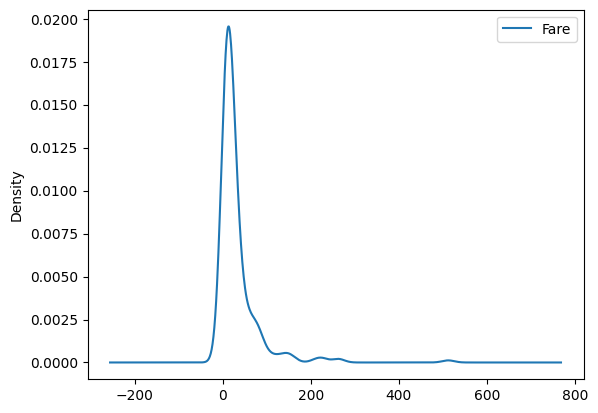

In [21]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(111)

# Original variable distribution
x_train['Fare'].plot(kind='kde', ax=ax)

# Variable imputed with the median
# x_train_trf['Fare'].plot(kind='kde', ax=ax, color='red')



# Add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')